<a href="https://colab.research.google.com/github/Git34Smakin/codez/blob/main/Copy_of_New_Cluster.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <center><b> Customer Segmentation </b></center>

# **1. Objective**
This case requires to develop a customer segmentation to understand customers behavior and sepparate them in different groups or cluster according to their preferences, and once the division is done, this information can be given to marketing team so they can plan the strategy accordingly.

### **Data Description :**
The sample Dataset summarizes the usage behavior of about 200 active customers during the last 3 months. The file is at a customer level with 5 behavioral variables.

### **Attribute Information :**
Following is the Data Dictionary for customer dataset :-

**CustomerID** : Unique ID assigned to the customer

**Gender** :Gender of the customer

**Age** : Age of the customer

**Annual Income (k$)** : Annual Income of the customee

**Spending Score** : Score assigned by the mall based on customer behavior and spending nature

# **2. Install & Import Libraries**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
# clustering algorithms
from sklearn.cluster import KMeans

# **3. Load Datasets**

In [9]:
# load dataset
from google.colab import drive
import pandas as pd

# Mount Google Drive
drive.mount('/content/drive')

# Load dataset
file_path = "/content/drive/MyDrive/dataset/Mall_Customers.csv"
data = pd.read_csv(file_path)

# Preview
print(data.head())
print(data.info())

Mounted at /content/drive
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None


# **4. Feature Engineering**

### 4.1. Drop Columns

In [10]:
# Drop CustomerID column (not useful for clustering)
data = data.drop(columns=['CustomerID'])

# If you also want to drop Gender (categorical, unless encoding)
# data = data.drop(columns=['Gender'])

# Preview updated dataset
data.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


### 4.2. Encoding Categorical Features

In [11]:
from sklearn.preprocessing import LabelEncoder

# Encode Gender column (Male=1, Female=0 for example)
le = LabelEncoder()
data['Gender'] = le.fit_transform(data['Gender'])

# Preview encoded dataset
data.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,19,15,39
1,1,21,15,81
2,0,20,16,6
3,0,23,16,77
4,0,31,17,40


### 4.3. Normalization

In [ ]:
# Scale the data
from sklearn.preprocessing import StandardScaler

# Select features for clustering
X = data[['Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']]

# Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert back to DataFrame for easier viewing
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

X_scaled.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1.128152,-1.424569,-1.738999,-0.434801
1,1.128152,-1.281035,-1.738999,1.195704
2,-0.886405,-1.352802,-1.700830,-1.715913
3,-0.886405,-1.137502,-1.700830,1.040418
4,-0.886405,-0.563369,-1.662660,-0.395980


# **5. Model Development**

### 5.1. Hyperparameter tuning

To find the best K value there are many techniques we can use.

1. **Elbow Method**: The elbow method finds the value of the optimal number of clusters using the total within-cluster sum of square values.
2. **Average silhouette method** : It is a measure of how well each data point fits its corresponding cluster. This method evaluates the quality of clustering. As a general rule, a high average silhouette width denotes better clustering output.
3. **Gap statistic method** : It is a measure of the value of gap statistics. Gap statistics is the difference between the total intracluster changes for various values of k compared to their expected values. The optimal number of clusters is the value that maximizes the value of gap statistics.

- Here we'll use **Elbow Method** to find the best K Value.

### 5.2. Elbow Method

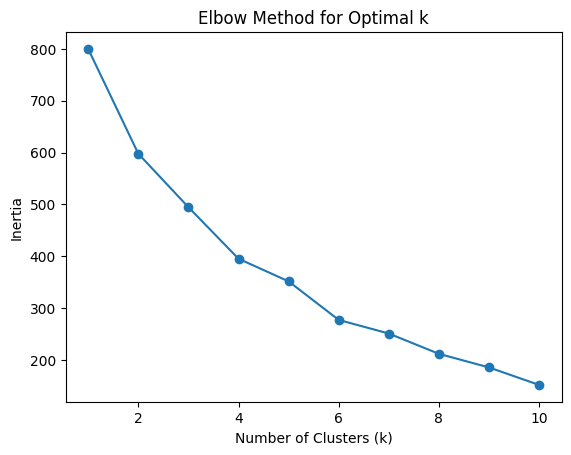

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Elbow Method
inertia = []
K = range(1, 11)

for k in K:
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

# Plot elbow curve
plt.plot(K, inertia, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.show()

From the above graph, inertia decreases as K increases because more clusters reduce within-cluster distances.

The best K is often at the “elbow” — the point where adding another cluster gives diminishing returns (the slope flattens).

For example, inertia drops sharply from K=1 to K=3, but only slightly after K=4 or 5, then K=5 may be optimal.

### 5.3 K-Means Clustering

In [ ]:

# Fit KMeans with chosen k (e.g., 5)
final_k = 5
kmeans = KMeans(n_clusters=final_k, random_state=42)
data['Cluster'] = kmeans.fit_predict(X_scaled)

# Preview cluster assignments
data.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,19,15,39,2
1,1,21,15,81,2
2,0,20,16,6,4
3,0,23,16,77,4
4,0,31,17,40,4


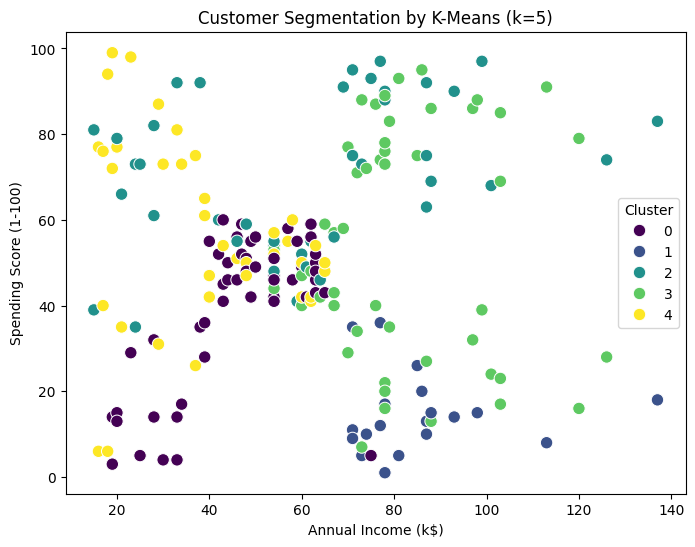

In [ ]:

# Preview with cluster labels
data.head()
import seaborn as sns

# Visualize clusters based on Income vs Spending Score
plt.figure(figsize=(8,6))
sns.scatterplot(x=data['Annual Income (k$)'],
                y=data['Spending Score (1-100)'],
                hue=data['Cluster'],
                palette='viridis',
                s=80)
plt.title('Customer Segmentation by K-Means (k=5)')
plt.show()